# Tutorial：Cell imputation on mouse hippocampus Slide-tags data

## Outline

1. Import packages
2. Load data
3. Batch effect assessment
4. Construct graphs and extract features
5. Microenvironment representations learning for scRNA-seq data
6. Optimal matching
7. Denoising
8. Cell imputation

## 1. Import packages

In [1]:
import scanpy as sc
import os
from pathlib import Path
import cellback as cb
import matplotlib.pyplot as plt
import numpy as np

## 2. Load data

Using matched mouse hippocampus scRNA-seq data, we accurately map single cells to their corresponding spatial locations, thereby performing cell imputation for the Slide-tags data.

In [2]:
#mouse hippocampus cell imputation
data_dir = Path("../CellBack/data/mousehippocampus/")
adata_sp = sc.read_h5ad(data_dir / "slide_tag.h5ad")
adata_sp.obsm['spatial'] = adata_sp.obsm['coordinate'].copy()
adata_sc = sc.read_h5ad(data_dir / "sc_seq.h5ad")
adata_sp.var_names_make_unique()
adata_sc.var_names_make_unique()
sc.pp.filter_cells(adata_sc, min_genes=200)
sc.pp.filter_genes(adata_sc, min_cells=3)

common_gene = adata_sp.var_names.intersection(adata_sc.var_names)
adata_sp = adata_sp[:, common_gene]
adata_sc = adata_sc[:, common_gene]

#Since the Slide-tags data has been normalized, we just normalize scRNA-seq data.
sc.pp.normalize_total(adata_sc, target_sum=1e4)
sc.pp.log1p(adata_sc)

## 3. Batch effect assessment

UMAP visualizations based on batch and cell type show no obvious batch effects between the two datasets; therefore, batch correction is not performed. We use the PCA-reduced representations as the low-dimensional embeddings for subsequent analyses.

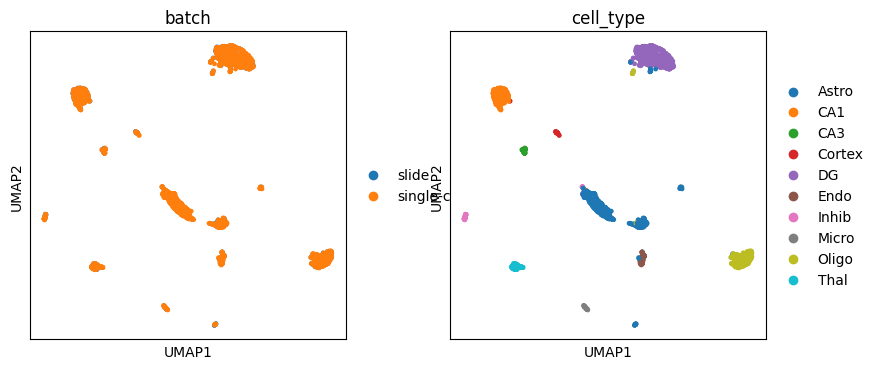

In [3]:
batch_categories = ["slide", "single-cell"]
adata_list = [adata_sp, adata_sc]
adata_merged = sc.concat(adata_list,
                        index_unique=None,
                        label="batch",
                        keys=batch_categories)

sc.pp.highly_variable_genes(
    adata_merged,
    flavor="seurat_v3",
    n_top_genes=2000,
    batch_key="batch",
    subset=True,
)

#check the batch effect
sc.pp.pca(adata_merged)
sc.pp.neighbors(adata_merged, n_pcs=15, n_neighbors=30)
sc.tl.umap(adata_merged, min_dist=0.1)
plt.rcParams["figure.figsize"] = (4, 4)
sc.pl.umap(adata_merged, color=["batch", "cell_type"])
#no significant batch effects, we neglect batch correction

In [4]:
adata_sc = adata_sc[:, adata_merged.var_names]
adata_sc.obsm['X_pca'] = adata_merged[adata_sc.obs_names, :].obsm['X_pca']
adata_sp = adata_sp[:, adata_merged.var_names]
adata_sp.obsm['X_pca'] = adata_merged[adata_sp.obs_names, :].obsm['X_pca']

#obtain micro-environment for slide-seq data based on banksy,
#higher lambda means higher importance of microenvironmental information, default 0.8.
lambda_list = [0.8]
adata_sp_micro, micro_weight = cb.utils.run_banksy(adata_sp, lambda_list=lambda_list)


Median distance to closest cell = 17.982428857598148

---- Ran median_dist_to_nearest_neighbour in 0.00 s ----


Median distance to closest cell = 17.9824

---- Ran generate_spatial_distance_graph in 0.00 s ----

---- Ran row_normalize in 0.00 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.03 s ----

---- Ran generate_spatial_distance_graph in 0.01 s ----

---- Ran theta_from_spatial_graph in 0.01 s ----

---- Ran row_normalize in 0.00 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.04 s ----

Runtime Jan-15-2026-20-21

2000 genes to be analysed:
Gene List:
Index(['Sox17', 'Rgs20', 'St18', 'Adhfe1', 'Prex2', 'A830018L16Rik', 'Eya1',
       'Gm28376', 'Kcnq5', 'Col19a1',
       ...
       'mt-Nd1', 'mt-Nd2', 'mt-Co2', 'mt-Atp8', 'mt-Nd3', 'mt-Nd4l', 'mt-Nd4',
       'mt-Nd5', 'mt-Nd6', 'mt-Cytb'],
      dtype='object', length=2000)

Check if X contains only finite (non-NAN) values
Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <839x839 sparse matrix of

## 4. Construct graphs and extract features

Edges among spatial cells are determined using parameter threshold_distance. Connections between spatial cells and single cells are established based on similarity in .obsm['X_pca'], where k specifies the number of most similar single cells linked to each spatial cell.

In [5]:
#edge_index
edge_index_intra = cb.utils.intra_spatial_proximity(adata_sp,
                                                          threshold_distance=65)
edge_index_inter = cb.utils.inter_correlation_calculation(adata_sc,
                                                                adata_sp, k=5, basis="X_pca")
edge_index = edge_index_intra + edge_index_inter

#feature matrix
lam = micro_weight
features, targets = cb.utils.extra_features(adata_sc,
                                                  adata_sp,
                                                  adata_sp_micro, lam=lam)

100%|██████████| 839/839 [00:02<00:00, 399.01it/s]


Mean degree(neighbors): 4.51668653158522


100%|██████████| 1661/1661 [01:23<00:00, 19.83it/s]


## 5. Microenvironment representations learning for scRNA-seq data

In [6]:
#train the model
celltype_list = adata_sc.obs['cell_type'].unique()
cb.micro_network_training(adata_sc=adata_sc,
                          adata_sp=adata_sp,
                          edge_index=edge_index,
                          features=features,
                          targets=targets,
                          cell_types=celltype_list,
                          epoch=30000)

Epoch 0, Loss: 7.0086
Epoch 1000, Loss: 1.4796
Epoch 2000, Loss: 1.1876
Epoch 3000, Loss: 1.0164
Epoch 4000, Loss: 0.9253
Epoch 5000, Loss: 0.9048
Epoch 6000, Loss: 0.8934
Epoch 7000, Loss: 0.8916
Epoch 8000, Loss: 0.8808
Epoch 9000, Loss: 0.7956
Epoch 10000, Loss: 0.7776
Epoch 11000, Loss: 0.8489
Epoch 12000, Loss: 0.8349
Epoch 13000, Loss: 0.7822
Epoch 14000, Loss: 0.7778
Epoch 15000, Loss: 0.8183
Epoch 16000, Loss: 0.7201
Epoch 17000, Loss: 0.7025
Epoch 18000, Loss: 0.7984
Epoch 19000, Loss: 0.7439
Epoch 20000, Loss: 0.7689
Epoch 21000, Loss: 0.7662
Epoch 22000, Loss: 0.7153
Epoch 23000, Loss: 0.7508
Epoch 24000, Loss: 0.6827
Epoch 25000, Loss: 0.7447
Epoch 26000, Loss: 0.6546
Epoch 27000, Loss: 0.7654
Epoch 28000, Loss: 0.6512
Epoch 29000, Loss: 0.6891


## 6. Optimal matching

We first perform cell-type proportion–guided optimal matching based on intrinsic and microenvironment gene expression similarity to obtain correspondences between the two datasets. Subsequently, we generate pseudo-spatial coordinates for single cells using one of two modes ('perturbation' or 'repetition'), which are stored in adata_sc.obsm['pseudo_space']. As this dataset does not exhibit an obvious spatially symmetric structure, we set mode = 'repetition', where the repetition parameter specifies the number of samplings according to cell-type proportion.

In [7]:
#optimal matching process
adata_sc = cb.optimal_matching.matching(adata_sp,
                              adata_sc,
                              mode='repetition',
                              repetition=100)

 Use 'repetition' mode. 


100%|██████████| 1661/1661 [01:30<00:00, 18.44it/s]


## 7. Denoising

Prior to cell imputation, we leverage the matched scRNA-seq data to denoise the Slide-tags data, ensuring that the two datasets are on the same scale. For each spatial cell, smoothing is performed by averaging expression vectors over the top k single cells that are most similar in both transcriptional profiles and microenvironmental context.

In [19]:
#denoising
slide = sc.read_h5ad(data_dir / "slide_tag.h5ad")
slide.obsm['spatial'] = slide.obsm['coordinate'].copy()
singlecell = sc.read_h5ad(data_dir / "sc_seq.h5ad")
singlecell.obsm['spatial'] = adata_sc.obsm['pseudo_space'].copy()
slide.var_names_make_unique()
singlecell.var_names_make_unique()

common_gene = slide.var_names.intersection(singlecell.var_names)
slide = slide[:, common_gene]
singlecell = singlecell[:, common_gene]

singlecell_X = singlecell.X.toarray()
adata_denoised = cb.denoising(adata_sp, adata_sc, singlecell_X, slide, k=100)

100%|██████████| 839/839 [00:07<00:00, 113.73it/s]


We evaluate the denoising performance using three metrics: the Davies–Bouldin Index, Silhouette Score, and Purity Score.

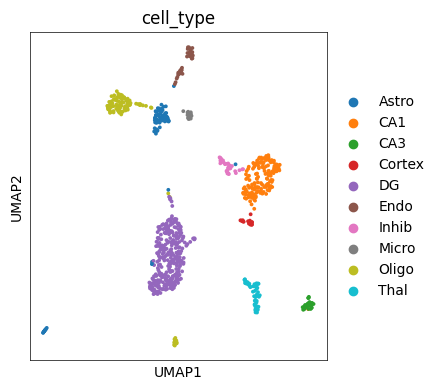

In [39]:
sc.pp.highly_variable_genes(slide, flavor="seurat_v3", n_top_genes=2000)
slide = slide[:, slide.var.highly_variable]
sc.tl.pca(slide, svd_solver="arpack")
sc.pp.neighbors(slide, n_neighbors=10, n_pcs=40)
sc.tl.umap(slide)

plt.rcParams["figure.figsize"] = (4.5, 4)
fig = sc.pl.umap(slide, color="cell_type", return_fig=True, size=30)
fig.tight_layout()
fig.show()

In [40]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

X = slide.obsm['X_umap']
labels = slide.obs['cell_type'].astype('category').cat.codes

sil_score = silhouette_score(X, labels)
db_index = davies_bouldin_score(X, labels)
print(f"Davies-Bouldin Index: {db_index:.4f}")
print(f"Silhouette Score: {sil_score:.4f}")

from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=slide.obs['cell_type'].nunique(), random_state=0)
cluster_labels = kmeans.fit_predict(X)

from sklearn.metrics.cluster import contingency_matrix
def purity_score(y_true, y_pred):
    contingency = contingency_matrix(y_true, y_pred)
    return np.sum(np.amax(contingency, axis=0)) / np.sum(contingency)

purity = purity_score(slide.obs['cell_type'].astype('category').cat.codes, cluster_labels)
print(f"Purity Score: {purity:.4f}")

Davies-Bouldin Index: 1.5214
Silhouette Score: 0.5164
Purity Score: 0.8892


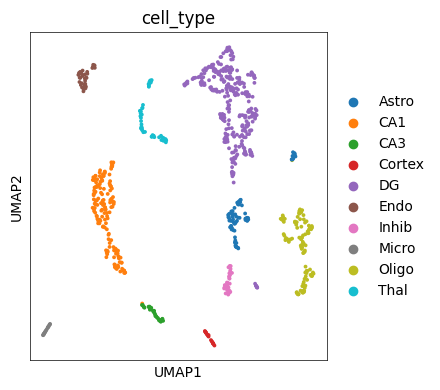

In [41]:
adata = adata_denoised.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=2000)
adata = adata[:, adata.var.highly_variable]
sc.tl.pca(adata, svd_solver="arpack")
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)
sc.tl.umap(adata)

plt.rcParams["figure.figsize"] = (4.5, 4)
fig = sc.pl.umap(adata, color="cell_type", return_fig=True, size=30)
fig.tight_layout()
fig.show()

In [42]:
X = adata.obsm['X_umap']
labels = adata.obs['cell_type'].astype('category').cat.codes

sil_score = silhouette_score(X, labels)
db_index = davies_bouldin_score(X, labels)
print(f"Davies-Bouldin Index of enhanced: {db_index:.4f}")
print(f"Silhouette Score of enhanced: {sil_score:.4f}")

kmeans = KMeans(n_clusters=adata.obs['cell_type'].nunique(), random_state=0)
cluster_labels = kmeans.fit_predict(X)
purity = purity_score(adata.obs['cell_type'].astype('category').cat.codes, cluster_labels)
print(f"Purity Score of enhanced: {purity:.4f}")

Davies-Bouldin Index of enhanced: 0.4733
Silhouette Score of enhanced: 0.5483
Purity Score of enhanced: 0.9190


## 8. Cell imputation

The cell imputation procedure is implemented using the cb.cell_imputation function. We visualize the spatial distributions of cells before and after cell imputation.

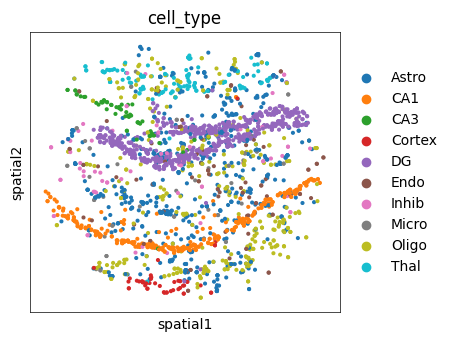

In [50]:
#visualization before and after cell imputation
#cell imputation
adata_imputation = cb.cell_imputation(adata_denoised, singlecell)

plt.rcParams["figure.figsize"] = (4, 5)
#after cell imputation
fig = sc.pl.spatial(adata_imputation,
              basis="spatial",
              color='cell_type',
              spot_size=30,
              return_fig=True)
fig.tight_layout()
fig.show()

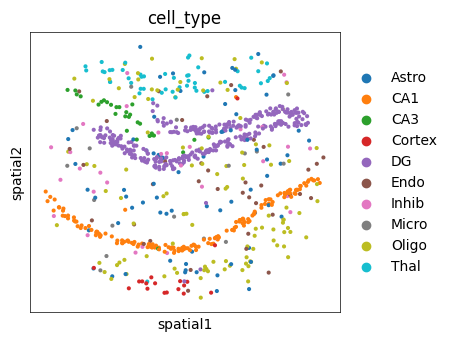

In [51]:
#before cell imputation
fig = sc.pl.spatial(slide,
              basis="spatial",
              color='cell_type',
              spot_size=30,
              return_fig=True)
fig.tight_layout()
fig.show()